# Projeto Prático 2.1 - Aprendizado Supervisionado no Neurônio Perceptron

**Redes Neurais Artificiais - 2026/2** - Escola Superior de Tecnologia (UEA)
- Profa. Elloá B. Guedes (ebgcosta@uea.edu.br)
- http://github.com/elloa

### Equipe

- Integrante 1 (github.com/jubcohen)
- Integrante 2 (github.com/portelapedro)

Este notebook implementa o algoritmo de treinamento do neurônio Perceptron de Rosenblatt. Ele está organizado em duas camadas:

1. **Funções reutilizáveis** (Seção 1): leitura dos dados, operações do neurônio, laço de treinamento, visualização e relatório.
2. **Partes da atividade** (Seção 2 em diante): cada parte apenas define seus parâmetros e chama as funções da Seção 1.

## 1. Funções reutilizáveis

In [1]:
%pip install prettytable

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from prettytable import PrettyTable  
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score,
                             recall_score, f1_score)
import pandas as pd

# Esquema de cores exigido pela atividade: classe 0 em vermelho, classe 1 em azul
CORES_CLASSES = {0: 'red', 1: 'blue'}
# identificador da dupla: (8 + 8) % 4 = 0
identificador = 0

### 1.1 Leitura dos dados

Cada arquivo contém um `numpy.ndarray` salvo em binário com dimensões `(m, 1, 3)`, em que cada exemplo é `(x1, x2, yd)`. A função devolve os atributos `X` com formato `(m, 2)` e os rótulos `yd` com formato `(m,)`.

O viés **não** é adicionado aqui: ele é responsabilidade do neurônio (função `adicionar_vies`). Assim, `X` continua representando apenas os pontos do $\mathbb{R}^2$ e pode ser usado diretamente nos gráficos e na divisão treino/teste.

In [3]:
def carregar_dados(caminho):
    """Lê um arquivo binário (m, 1, 3) e devolve X (m, 2) e yd (m,)."""
    dados = np.load(caminho).reshape(-1, 3)
    X = dados[:, :2]
    yd = dados[:, 2].astype(int)
    print(np.load(caminho).shape)
    print(f"[{caminho}] {X.shape[0]} exemplos carregados "
          f"(classe 0: {np.sum(yd == 0)}, classe 1: {np.sum(yd == 1)}).")
    return X, yd

### 1.2 Operações do neurônio

- `adicionar_vies`: acrescenta a entrada fixa $x_0 = -1$, de modo que $w_0$ faz o papel do limiar.
- `inicializar_pesos`: sorteia $w_i \sim U(a, b)$ para o intervalo informado.
- `degrau`: função de ativação degrau com limiar $\vartheta$ (padrão $\vartheta = 0$). Funciona tanto para um único valor quanto para um vetor.
- `prever`: calcula a saída do neurônio para **todos** os exemplos de uma vez, com uma única multiplicação matricial.

In [4]:
def adicionar_vies(X):
    """Acrescenta a coluna x0 = -1 à esquerda de X."""
    return np.hstack((-np.ones((X.shape[0], 1)), X))


def inicializar_pesos(intervalo, n_pesos=3, rng=None):
    """Sorteia o vetor de pesos w ~ U(intervalo[0], intervalo[1])."""
    rng = np.random.default_rng(rng)
    return rng.uniform(intervalo[0], intervalo[1], n_pesos)


def degrau(u, theta=0.0):
    """Função de ativação degrau: 1 se u >= theta, senão 0."""
    return np.where(u >= theta, 1, 0)


def prever(X, w, theta=0.0):
    """Saída do neurônio para todos os exemplos de X (sem a coluna de viés)."""
    return degrau(adicionar_vies(X) @ w, theta)

### 1.3 Treinamento

`treinar_perceptron` concentra a regra de aprendizado do Perceptron, $\mathbf{w} \leftarrow \mathbf{w} + \eta\,e\,\mathbf{x}$, com $e = y_d - y$. O mesmo código atende às três partes da atividade por meio dos parâmetros:

| Parâmetro | Parte I | Parte II | Parte III |
|---|---|---|---|
| `eta`, `intervalo` | 0,1 e (−0,5, +0,5) | as 6 combinações | recomendação da literatura |
| `max_epocas` | `None` (até convergir) | `None` (até convergir) | 100 |
| `embaralhar` | `False` | `False` | `True` |
| `rng` | livre | livre | semente da equipe |

**Critério de parada.** O treinamento termina quando uma época inteira passa sem erros (convergência) ou quando `max_epocas` é atingido. Se uma época não tem erros, os pesos não mudam e todas as épocas seguintes também não teriam erros, então parar ali é sempre seguro.

**Contagem de épocas.** `epocas` é o número de épocas executadas, **incluindo** a última, sem erros, que comprova a convergência. Cada erro gera exatamente um ajuste, então o total de ajustes é a soma dos erros de todas as épocas.

> ⚠️ Com `max_epocas=None` em um problema **não** linearmente separável, o laço não termina. Na Parte III, sempre informe `max_epocas`.

In [5]:
@dataclass
class ResultadoTreinamento:
    """Tudo o que uma execução de treinamento produz."""
    w_inicial: np.ndarray
    w_final: np.ndarray
    total_ajustes: int
    epocas: int
    erros_por_epoca: list
    convergiu: bool


def treinar_perceptron(X, yd, eta, intervalo=(-0.5, 0.5), theta=0.0,
                       max_epocas=None, embaralhar=False, rng=None, verbose=False):
    """
    Treina um Perceptron pela regra de aprendizado de Rosenblatt.

    X          : atributos (m, 2), sem a coluna de viés
    yd         : saídas desejadas (m,)
    eta        : taxa de aprendizado
    intervalo  : (a, b) da distribuição uniforme dos pesos iniciais
    theta      : limiar da função degrau
    max_epocas : None = treina até convergir; inteiro = limite de épocas
    embaralhar : se True, apresenta os exemplos em ordem aleatória a cada época
    rng        : semente (int) ou np.random.Generator, para reprodutibilidade
    verbose    : imprime os pesos iniciais e o número de erros por época
    """
    rng = np.random.default_rng(rng)
    Xb = adicionar_vies(X)
    w_inicial = inicializar_pesos(intervalo, Xb.shape[1], rng)
    w = w_inicial.copy()

    if verbose:
        print(f"Vetor inicial de pesos: {w_inicial}")

    erros_por_epoca = []
    convergiu = False
    while max_epocas is None or len(erros_por_epoca) < max_epocas:
        ordem = rng.permutation(len(Xb)) if embaralhar else np.arange(len(Xb))
        erros = 0
        for i in ordem:
            e = yd[i] - degrau(Xb[i] @ w, theta)
            if e != 0:
                w = w + eta * e * Xb[i]
                erros += 1
        erros_por_epoca.append(erros)

        if verbose:
            print(f"  Época {len(erros_por_epoca):>3}: {erros} erros")
        if erros == 0:
            convergiu = True
            break

    return ResultadoTreinamento(
        w_inicial=w_inicial,
        w_final=w,
        total_ajustes=int(np.sum(erros_por_epoca)),
        epocas=len(erros_por_epoca),
        erros_por_epoca=erros_por_epoca,
        convergiu=convergiu,
    )

### 1.4 Visualização

A reta de decisão é o conjunto de pontos em que $u = \vartheta$:

$$-w_0 + w_1 x_1 + w_2 x_2 = \vartheta \quad\Longrightarrow\quad x_2 = \frac{\vartheta + w_0 - w_1 x_1}{w_2}$$

As funções recebem um `ax` opcional. Assim, `plotar_solucao` serve tanto para um gráfico isolado (Parte I) quanto para gráficos lado a lado (Parte III), e `plotar_dados` sozinha serve para o gráfico inicial da Parte III. As regiões de decisão são coloridas com `prever`, a mesma função usada para avaliar o modelo.

In [6]:
def plotar_dados(X, yd, ax=None, titulo=None):
    """Dispersão dos exemplos: classe 0 em vermelho e classe 1 em azul."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    for classe, cor in CORES_CLASSES.items():
        mascara = yd == classe
        ax.scatter(X[mascara, 0], X[mascara, 1], c=cor, s=18, alpha=0.7,
                   edgecolors='none', label=f'Classe {classe}')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.grid(True, alpha=0.3)
    if titulo:
        ax.set_title(titulo)
    ax.legend(loc='best')
    return ax


def plotar_reta_decisao(w, ax, theta=0.0, regioes=True):
    """Desenha a reta de decisão (e, opcionalmente, as regiões) nos limites atuais de ax."""
    xlim, ylim = ax.get_xlim(), ax.get_ylim()

    if regioes:
        g1, g2 = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
        grade = np.column_stack((g1.ravel(), g2.ravel()))
        z = prever(grade, w, theta).reshape(g1.shape)
        ax.contourf(g1, g2, z, levels=[-0.5, 0.5, 1.5],
                    colors=[CORES_CLASSES[0], CORES_CLASSES[1]], alpha=0.08, zorder=0)

    if np.isclose(w[2], 0):  # reta vertical: x1 = (theta + w0) / w1
        ax.axvline((theta + w[0]) / w[1], color='black', linestyle='--',
                   linewidth=2, label='Reta de decisão')
    else:
        x1 = np.linspace(*xlim, 200)
        x2 = (theta + w[0] - w[1] * x1) / w[2]
        ax.plot(x1, x2, color='black', linestyle='--', linewidth=2,
                label='Reta de decisão')

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.legend(loc='best')
    return ax


def plotar_solucao(X, yd, w, ax=None, titulo=None, theta=0.0):
    """Exemplos + reta de decisão obtida pelo treinamento."""
    ax = plotar_dados(X, yd, ax=ax, titulo=titulo)
    return plotar_reta_decisao(w, ax, theta)

### 1.5 Relatório do treinamento

In [53]:
def imprimir_resumo(resultado, X=None, yd=None):
    """Imprime os números finais de uma execução e, se X e yd forem dados, a acurácia."""
    status = "convergiu" if resultado.convergiu else "NÃO convergiu (limite de épocas)"
    print("-" * 60)
    print(f"Treinamento {status}.")
    print(f"Número total de ajustes no vetor de pesos: {resultado.total_ajustes}")
    # só faz sentido falar em "convergência" quando ela aconteceu
    rotulo = "até a convergência" if resultado.convergiu else "executadas"
    print(f"Número de épocas {rotulo}: {resultado.epocas}")
    print(f"Vetor inicial de pesos: {resultado.w_inicial}")
    print(f"Vetor final de pesos:   {resultado.w_final}")
    if X is not None and yd is not None:
        acuracia = np.mean(prever(X, resultado.w_final) == yd)
        print(f"Acurácia sobre os dados fornecidos: {acuracia:.2%}")
    print("-" * 60)

### 1.6 Experimentação (Parte II)

- `executar_experimentos`: roda `n_repeticoes` treinamentos para cada combinação $\eta \times I$ e devolve um `DataFrame` com uma linha por execução (configuração, ajustes, épocas).
- `tabela_experimentos`: resume o `DataFrame` na tabela pedida (média ± desvio padrão dos ajustes, menor e maior número de épocas) usando `prettytable`.
- `plotar_boxplots`: um boxplot por configuração, para ajustes e para épocas.

Um único `np.random.Generator` com a semente da equipe é compartilhado por todas as execuções: cada repetição sorteia pesos iniciais diferentes, mas o experimento inteiro é reprodutível.

In [21]:
def rotulo_config(eta, intervalo):
    # Rótulo curto usado na tabela e nos boxplots, p.ex. 'η=0.4 | (-100, +100)'
    a, b = intervalo
    return f"η={eta} | ({a:g}, +{b:g})"


def executar_experimentos(X, yd, etas, intervalos, n_repeticoes=10, theta=0.0, rng=None, max_epocas=None, verbose=True):
    # Executa todas as combinações eta x intervalo, n_repeticoes vezes cada
    rng = np.random.default_rng(rng)
    linhas = []
    for eta in etas:
        for intervalo in intervalos:
            for rep in range(1, n_repeticoes + 1):
                # Mesmo algoritmo da Parte I: até convergir, sem embaralhar
                r = treinar_perceptron(X, yd, eta=eta, intervalo=intervalo,
                                       theta=theta, max_epocas=max_epocas, rng=rng)

                # Mostra o progresso de cada execução
                if verbose:
                    aviso = '' if r.convergiu else '  <-- NÃO convergiu'
                    print(f"{rotulo_config(eta, intervalo):<22} rep {rep:>2}: "
                          f"{r.epocas:>4} épocas, {r.total_ajustes:>6} ajustes{aviso}")

                linhas.append({
                    'eta': eta,
                    'intervalo': intervalo,
                    'config': rotulo_config(eta, intervalo),
                    'repeticao': rep,
                    'ajustes': r.total_ajustes,
                    'epocas': r.epocas,
                    'convergiu': r.convergiu,
                })
    return pd.DataFrame(linhas)


def tabela_experimentos(df):
    # Resume cada configuração: ajustes (média ± desvio), min e max épocas
    tabela = PrettyTable()
    tabela.field_names = ['Taxa de Aprendizado', 'Intervalo de Pesos',
                          'Qtde Ajustes', 'Min Épocas', 'Max Épocas']
    # sort=False preserva a ordem em que as configurações foram executadas
    for (eta, intervalo), g in df.groupby(['eta', 'intervalo'], sort=False):
        a, b = intervalo
        tabela.add_row([
            f"η = {eta}",
            f"({a:g}, +{b:g})",
            f"{g['ajustes'].mean():.2f} ± {g['ajustes'].std(ddof=1):.2f}",
            int(g['epocas'].min()),
            int(g['epocas'].max()),
        ])
    return tabela


def plotar_boxplots(df, titulo=None):
    # Um boxplot por configuração, para ajustes (esquerda) e épocas (direita)
    configs = list(dict.fromkeys(df['config']))  # ordem de execução
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, coluna, nome in zip(axes, ['ajustes', 'epocas'],
                                ['Número de ajustes', 'Número de épocas']):
        dados = [df.loc[df['config'] == c, coluna].values for c in configs]
        ax.boxplot(dados, showmeans=True)
        ax.set_xticks(range(1, len(configs) + 1))
        ax.set_xticklabels(configs, rotation=30, ha='right')
        ax.set_ylabel(nome)
        ax.set_title(f'{nome} por configuração')
        ax.grid(True, axis='y', alpha=0.3)
    if titulo:
        fig.suptitle(titulo)
    fig.tight_layout()
    return fig, axes

### 1.7 Validação *holdout* e métricas (Parte III)

- `dividir_holdout`: embaralha os índices com a semente informada e separa a fração de treino; o restante vira teste. Feita com `numpy`, já que o enunciado libera o `sklearn` apenas para as métricas.
- `avaliar_classificador`: acurácia, precisão, revocação e *F-Score* com `sklearn.metrics`, considerando a classe 1 como positiva.
- `plotar_treino_teste`: os dois gráficos lado a lado (treino e teste) com a mesma reta de decisão.

In [43]:
def dividir_holdout(X, yd, frac_treino=0.7, semente=None):
    # Divide aleatoriamente os exemplos em treino (frac_treino) e teste (resto)
    rng = np.random.default_rng(semente)
    indices = rng.permutation(len(X)) # gera a ordem aleatória dos exemplos
    n_treino = int(round(frac_treino * len(X))) # 70% de 800 = 560 exemplos para treino
    i_treino, i_teste = indices[:n_treino], indices[n_treino:] # corta a lista que está embaralhada em duas
    return X[i_treino], X[i_teste], yd[i_treino], yd[i_teste]


def avaliar_classificador(yd, y):
    # Métricas de desempenho (classe positiva = 1)
    # yd a saida desejada e y a prevista
    return {
        'Acurácia': accuracy_score(yd, y),
        'Precisão': precision_score(yd, y, zero_division=0),
        'Revocação': recall_score(yd, y, zero_division=0),
        'F-Score': f1_score(yd, y, zero_division=0),
    }


def plotar_treino_teste(X_treino, yd_treino, X_teste, yd_teste, w, theta=0.0,
                        titulo=None):
    # Mesma reta de decisão sobre os dados de treino (esquerda) e de teste (direita)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

    # devolve a média da previsão do Perceptron para todos os pontos de uma vez
    acc_treino = np.mean(prever(X_treino, w, theta) == yd_treino)
    acc_teste = np.mean(prever(X_teste, w, theta) == yd_teste)

    plotar_solucao(X_treino, yd_treino, w, ax=ax1, theta=theta,
                   titulo=f'Conjunto de Treino ({len(X_treino)} exemplos, '
                          f'acurácia {acc_treino:.2%})')
    plotar_solucao(X_teste, yd_teste, w, ax=ax2, theta=theta,
                   titulo=f'Conjunto de Teste ({len(X_teste)} exemplos, '
                          f'acurácia {acc_teste:.2%})')
    if titulo:
        fig.suptitle(titulo)
    fig.tight_layout()
    return fig, (ax1, ax2)

## 2. Parte I — Resolvendo um Problema Linearmente Separável

Configuração exigida: arquivo `dataAll20262.txt`, função degrau com $\vartheta = 0$, $\eta = 0{,}1$ e pesos iniciais $w_i \sim U(-0{,}5, +0{,}5)$, treinando até a convergência. Como o problema é linearmente separável, o teorema de convergência do Perceptron garante que o algoritmo termina com zero erros.

In [9]:
ARQUIVO_PARTE1 = 'dataAll20262.txt'
ETA_PARTE1 = 0.1
INTERVALO_PARTE1 = (-0.5, 0.5)
THETA = 0.0

X_p1, yd_p1 = carregar_dados(ARQUIVO_PARTE1)

(1000, 1, 3)
[dataAll20262.txt] 1000 exemplos carregados (classe 0: 500, classe 1: 500).


In [10]:
resultado_p1 = treinar_perceptron(X_p1, yd_p1, eta=ETA_PARTE1,
                                  intervalo=INTERVALO_PARTE1, theta=THETA,
                                  verbose=True)
imprimir_resumo(resultado_p1, X_p1, yd_p1)

Vetor inicial de pesos: [-0.47677033 -0.39441549 -0.15783237]
  Época   1: 37 erros
  Época   2: 4 erros
  Época   3: 0 erros
------------------------------------------------------------
Treinamento convergiu.
Número total de ajustes no vetor de pesos: 41
Número de épocas até a convergência:       3
Vetor inicial de pesos: [-0.47677033 -0.39441549 -0.15783237]
Vetor final de pesos:   [  -0.57677033   69.26795096 -353.66771996]
Acurácia sobre os dados fornecidos: 100.00%
------------------------------------------------------------


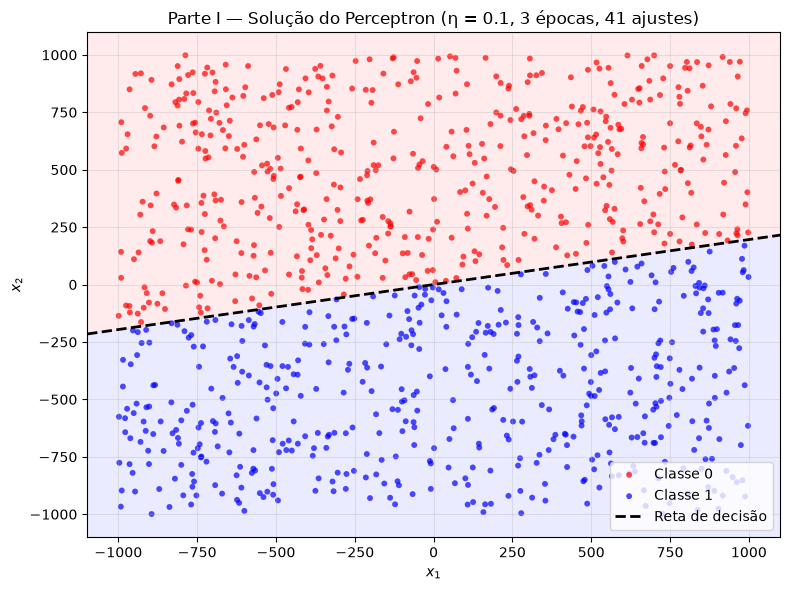

In [11]:
plotar_solucao(X_p1, yd_p1, resultado_p1.w_final, theta=THETA,
               titulo=f'Parte I — Solução do Perceptron '
                      f'(η = {ETA_PARTE1}, {resultado_p1.epocas} épocas, '
                      f'{resultado_p1.total_ajustes} ajustes)')
plt.tight_layout()
plt.show()

## 3. Parte II — Experimentação

Com identificador **0**, a equipe usa o arquivo `data020262.txt`. O algoritmo é o mesmo da Parte I (degrau com $\vartheta = 0$, treino até a convergência), repetido **10 vezes** para cada uma das 6 configurações

$$\eta \times I = \{0{,}4;\ 0{,}1;\ 0{,}01\} \times \{(-100, +100),\ (-0{,}5, +0{,}5)\}.$$

In [41]:
ARQUIVO_PARTE2 = f'data{identificador}20262.txt'
ETAS_PARTE2 = [0.4, 0.1, 0.01]
INTERVALOS_PARTE2 = [(-100, 100), (-0.5, 0.5)]
N_REPETICOES = 10
MAX_EPOCAS_PARTE2 = None

NORMALIZAR = False

X_p2, yd_p2 = carregar_dados(ARQUIVO_PARTE2)

if NORMALIZAR:
    X_p2 = X_p2 / np.abs(X_p2).max()
    print("Atributos normalizados para [-1, 1].")

(1000, 1, 3)
[data020262.txt] 1000 exemplos carregados (classe 0: 566, classe 1: 434).


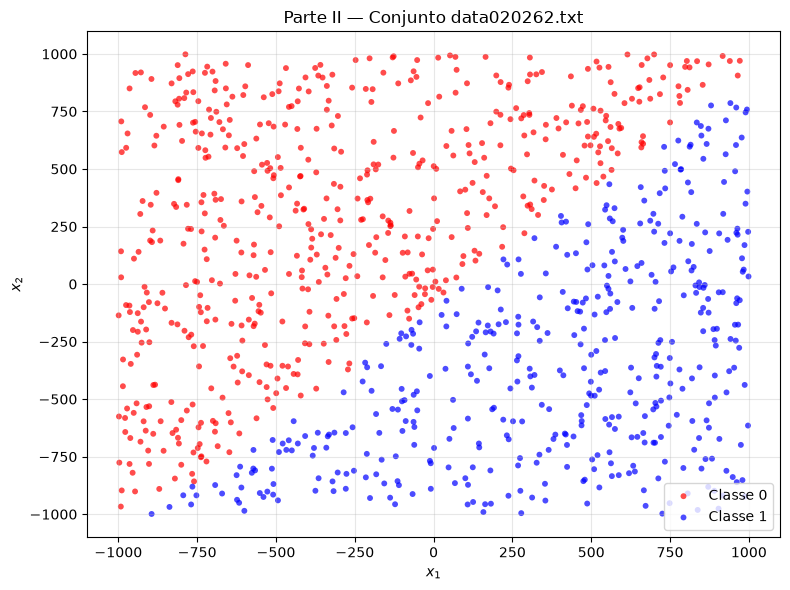

In [27]:
# Visão geral do conjunto
plotar_dados(X_p2, yd_p2, titulo=f'Parte II — Conjunto {ARQUIVO_PARTE2}')
plt.tight_layout()
plt.show()

In [42]:
# gerador único com a semente da equipe: cada repetição sorteia pesos diferentes,
# mas o experimento inteiro pode ser reproduzido
rng_p2 = np.random.default_rng(identificador)

resultados = []          # uma linha por configuração (vai para a tabela)
ajustes_por_config = {}  # listas completas das 10 repetições (vão para os boxplots)
epocas_por_config = {}
nao_convergiram = 0

for eta in ETAS_PARTE2:
    for intervalo in INTERVALOS_PARTE2:
        ajustes_repeticoes = []
        epocas_repeticoes = []

        for repeticao in range(N_REPETICOES):
            # mesmo treinamento da Parte I, com o teto de épocas
            r = treinar_perceptron(X_p2, yd_p2, eta=eta, intervalo=intervalo,
                                   theta=THETA, max_epocas=MAX_EPOCAS_PARTE2,
                                   rng=rng_p2)
            ajustes_repeticoes.append(r.total_ajustes)
            epocas_repeticoes.append(r.epocas)
            if not r.convergiu:
                nao_convergiram += 1

        # rótulo curto da configuração, usado nos boxplots
        rotulo = f"η={eta}\n({intervalo[0]:g}, +{intervalo[1]:g})"
        ajustes_por_config[rotulo] = ajustes_repeticoes
        epocas_por_config[rotulo] = epocas_repeticoes

        media = np.mean(ajustes_repeticoes)
        desvio_padrao = np.std(ajustes_repeticoes)
        min_epocas = np.min(epocas_repeticoes)
        max_epocas = np.max(epocas_repeticoes)

        resultados.append((eta, intervalo, float(media), float(desvio_padrao),
                           int(min_epocas), int(max_epocas)))

        # progresso: mostra cada configuração assim que termina
        print(f"η = {eta:<5} I = {str(intervalo):<12} -> "
              f"ajustes {media:.2f} ± {desvio_padrao:.2f}, "
              f"épocas {min_epocas}–{max_epocas}")

print(f"\nExecuções que NÃO convergiram em {MAX_EPOCAS_PARTE2} épocas: "
      f"{nao_convergiram} de {len(ETAS_PARTE2) * len(INTERVALOS_PARTE2) * N_REPETICOES}")

KeyboardInterrupt: 

In [39]:
tabela = PrettyTable()

tabela.field_names = ["Taxa de Aprendizado", "Intervalo de Pesos",
                      "Qtde Ajustes", "Min Épocas", "Max Épocas"]

for linha in resultados:
    eta, intervalo, media, desvio, min_epocas, max_epocas = linha
    ajustes_formatado = f"{media:.2f} ± {desvio:.2f}"

    # adiciona uma linha na tabela com os valores na ordem das colunas definidas
    tabela.add_row([f"η = {eta}", f"({intervalo[0]:g}, +{intervalo[1]:g})",
                    ajustes_formatado, min_epocas, max_epocas])

print(tabela)

+---------------------+--------------------+---------------------+------------+------------+
| Taxa de Aprendizado | Intervalo de Pesos |     Qtde Ajustes    | Min Épocas | Max Épocas |
+---------------------+--------------------+---------------------+------------+------------+
|       η = 0.4       |    (-100, +100)    |  365111.80 ± 114.08 |   10000    |   10000    |
|       η = 0.4       |    (-0.5, +0.5)    |  365155.20 ± 353.36 |   10000    |   10000    |
|       η = 0.1       |    (-100, +100)    |  365229.80 ± 165.18 |   10000    |   10000    |
|       η = 0.1       |    (-0.5, +0.5)    |  365282.60 ± 293.47 |   10000    |   10000    |
|       η = 0.01      |    (-100, +100)    | 367655.00 ± 2391.95 |   10000    |   10000    |
|       η = 0.01      |    (-0.5, +0.5)    |  365376.20 ± 196.75 |   10000    |   10000    |
+---------------------+--------------------+---------------------+------------+------------+


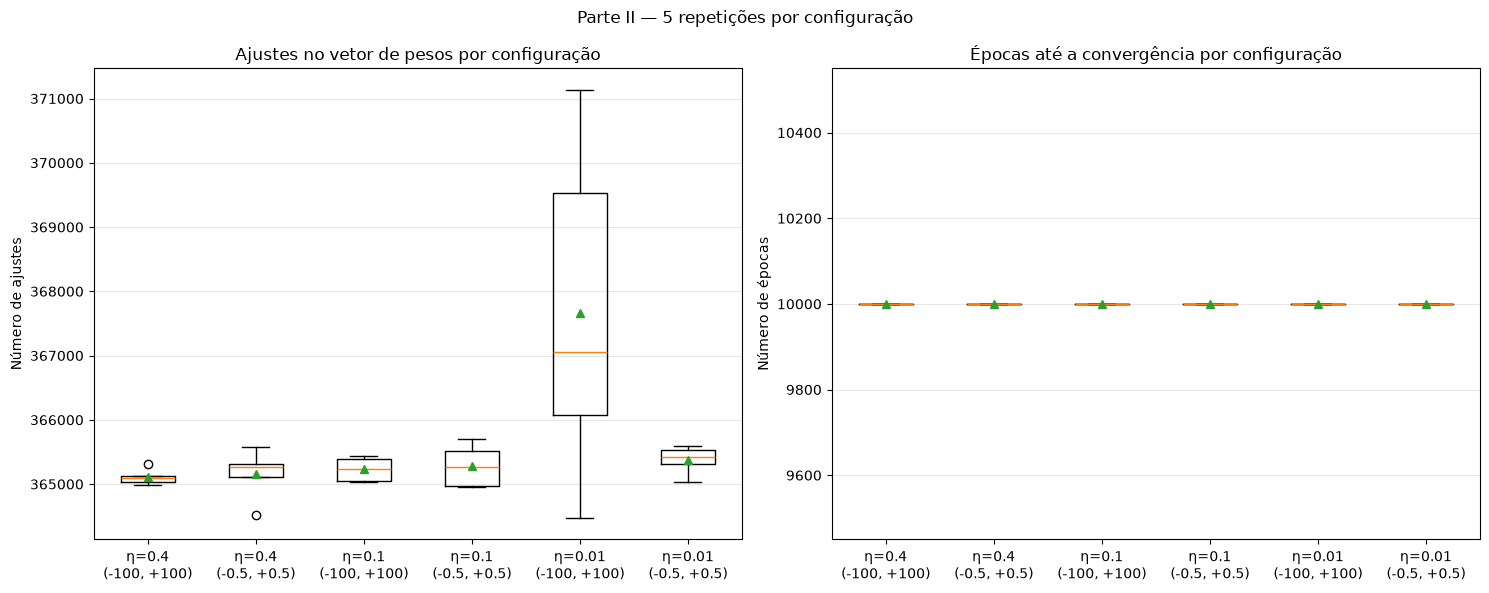

In [40]:
# um boxplot por configuração: ajustes à esquerda, épocas à direita
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
rotulos = list(ajustes_por_config.keys())

ax1.boxplot(list(ajustes_por_config.values()), showmeans=True)
ax1.set_xticks(range(1, len(rotulos) + 1))
ax1.set_xticklabels(rotulos)
ax1.set_ylabel('Número de ajustes')
ax1.set_title('Ajustes no vetor de pesos por configuração')
ax1.grid(True, axis='y', alpha=0.3)

ax2.boxplot(list(epocas_por_config.values()), showmeans=True)
ax2.set_xticks(range(1, len(rotulos) + 1))
ax2.set_xticklabels(rotulos)
ax2.set_ylabel('Número de épocas')
ax2.set_title('Épocas até a convergência por configuração')
ax2.grid(True, axis='y', alpha=0.3)

fig.suptitle(f'Parte II — {N_REPETICOES} repetições por configuração')
plt.tight_layout()
plt.show()

In [30]:
# 6 configurações x 10 repetições = 60 treinamentos (semente da equipe para reprodutibilidade)
df_p2 = executar_experimentos(X_p2, yd_p2, ETAS_PARTE2, INTERVALOS_PARTE2,
                              n_repeticoes=N_REPETICOES, theta=THETA,
                              rng=identificador)

print(f"Execuções que convergiram: {df_p2['convergiu'].sum()} de {len(df_p2)}")
print(tabela_experimentos(df_p2))

η=0.4 | (-100, +100)   rep  1: 241037 épocas, 2814793 ajustes
η=0.4 | (-0.5, +0.5)   rep  1: 240203 épocas, 2809443 ajustes
Unexpected exception formatting exception. Falling back to standard exception


Traceback (most recent call last):
  File "/opt/anaconda3/envs/rna/lib/python3.11/site-packages/IPython/core/interactiveshell.py", line 3748, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/1k/381_wpyj4zgfd_284h2ngml40000gn/T/ipykernel_66850/2872608771.py", line 2, in <module>
    df_p2 = executar_experimentos(X_p2, yd_p2, ETAS_PARTE2, INTERVALOS_PARTE2,
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/1k/381_wpyj4zgfd_284h2ngml40000gn/T/ipykernel_66850/4215477799.py", line 15, in executar_experimentos
    r = treinar_perceptron(X, yd, eta=eta, intervalo=intervalo,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/1k/381_wpyj4zgfd_284h2ngml40000gn/T/ipykernel_66850/2747401931.py", line None, in treinar_perceptron
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/anaconda3/envs/r

## 4. Parte III - Validação *Holdout* em Problema Não-Linearmente Separável

Arquivo `dataHoldout.txt`, dividido aleatoriamente em 70% para treino e 30% para teste, com semente igual ao identificador da equipe (0). 

Configuração do neurônio:

| Item | Valor | 
|---|---|
| Ativação | degrau, $\vartheta = 0$ | 
| $\eta$ | 0,1 | 
| Pesos iniciais | $U(-0{,}5, +0{,}5)$ | 
| Épocas | 100, com os exemplos em ordem aleatória a cada época | 

Como o problema não é linearmente separável, nenhuma época termina sem erros: o treino sempre roda as 100 épocas e o vetor final é a "solução possível".

In [45]:
ARQUIVO_PARTE3 = 'dataHoldout20262.txt'
ETA_PARTE3 = 0.1
INTERVALO_PARTE3 = (-0.5, 0.5)
EPOCAS_PARTE3 = 100
FRAC_TREINO = 0.7

X_p3, yd_p3 = carregar_dados(ARQUIVO_PARTE3)

(1000, 3)
[dataHoldout20262.txt] 1000 exemplos carregados (classe 0: 492, classe 1: 508).


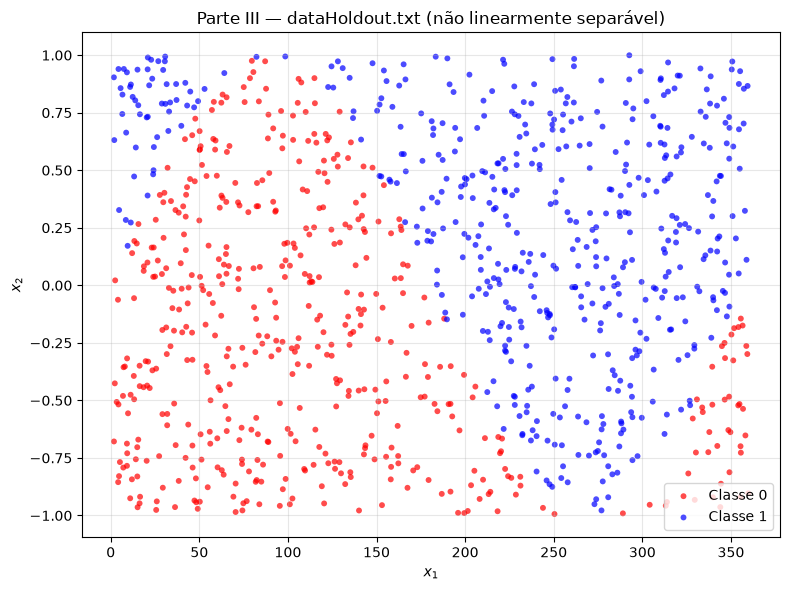

In [46]:
# gráfico inicial: as classes se misturam, logo nenhuma reta as separa sem erros
plotar_dados(X_p3, yd_p3, titulo='Parte III — dataHoldout.txt (não linearmente separável)')
plt.tight_layout()
plt.show()

In [47]:
# Divisão holdout 70/30 com a semente da equipe
X_treino, X_teste, yd_treino, yd_teste = dividir_holdout(
    X_p3, yd_p3, frac_treino=FRAC_TREINO, semente=identificador)

print("Formato treino:", X_treino.shape)
print("Formato teste: ", X_teste.shape)

Formato treino: (700, 2)
Formato teste:  (300, 2)


In [56]:
# Treinamento
# ESCALA_P3 = np.abs(X_treino).max()
resultado_p3 = treinar_perceptron(X_treino, yd_treino, eta=ETA_PARTE3,
                                  intervalo=INTERVALO_PARTE3, theta=THETA,
                                  max_epocas=EPOCAS_PARTE3, embaralhar=True,
                                  rng=identificador)

# resultado_p3.w_final = resultado_p3.w_final / np.array([1, ESCALA_P3, ESCALA_P3])
# print(f"Atributos de treino divididos por {ESCALA_P3:.2f}")
imprimir_resumo(resultado_p3)

------------------------------------------------------------
Treinamento NÃO convergiu (limite de épocas).
Número total de ajustes no vetor de pesos: 29618
Número de épocas executadas: 100
Vetor inicial de pesos: [ 0.13696169 -0.23021329 -0.45902648]
Vetor final de pesos:   [663.33696169   4.61539835 615.94427904]
------------------------------------------------------------


In [57]:
# Previsão do neurônio para todos os exemplos de teste e de treino (vetorizada, sem listas)
y_teste = prever(X_teste, resultado_p3.w_final, THETA)
y_treino = prever(X_treino, resultado_p3.w_final, THETA)

print("Primeiras 10 previsões (teste):", y_teste[:10])
print("Primeiros 10 rótulos reais:    ", yd_teste[:10])

Primeiras 10 previsões (teste): [1 0 0 0 1 1 1 1 1 1]
Primeiros 10 rótulos reais:     [1 1 1 0 1 1 1 1 0 0]


### 4.1 Matriz de confusão (conjunto de teste)

Matriz de Confusão (linhas = real, colunas = previsto):
[[107  37]
 [ 16 140]]


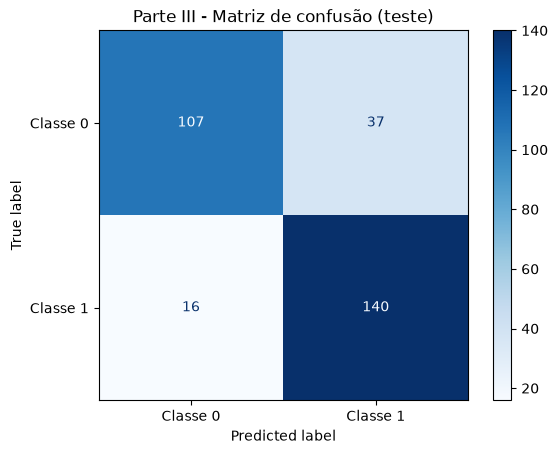

In [58]:
matriz_confusao = confusion_matrix(yd_teste, y_teste, labels=[0, 1])

print("Matriz de Confusão (linhas = real, colunas = previsto):")
print(matriz_confusao)

ConfusionMatrixDisplay(matriz_confusao, display_labels=['Classe 0', 'Classe 1']).plot(cmap='Blues')
plt.title('Parte III - Matriz de confusão (teste)')
plt.show()

### 4.2 e 4.3 Acurácia, precisão, revocação e *F-Score*

### 4.4 Qualidade da solução perante o conjunto de teste

### 4.5 Solução nos conjuntos de treino e de teste

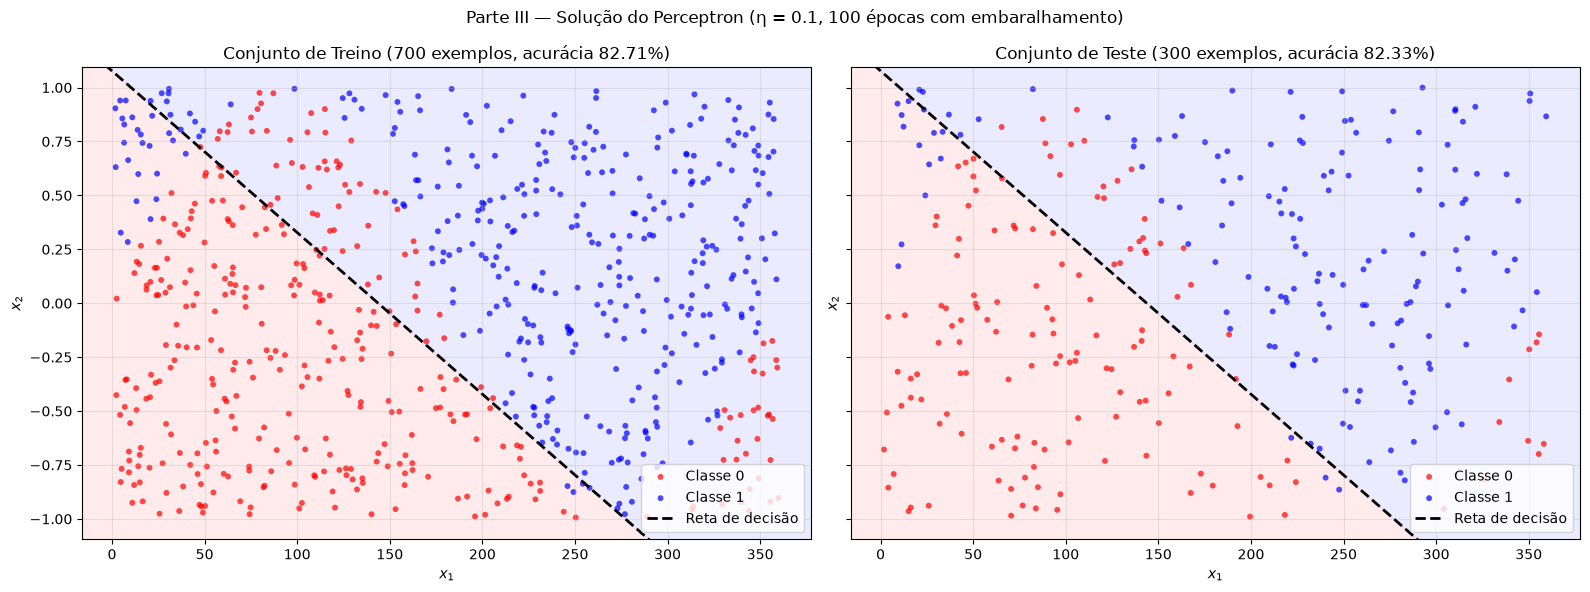

In [59]:
plotar_treino_teste(X_treino, yd_treino, X_teste, yd_teste, resultado_p3.w_final,
                    theta=THETA,
                    titulo=f'Parte III — Solução do Perceptron '
                           f'(η = {ETA_PARTE3}, {EPOCAS_PARTE3} épocas com embaralhamento)')
plt.show()